# Предобработка данных о жилых домах Красноярска

Источник — лист «Данные» книги **датасет.xlsx**. Держите её и `krasnoyarsk_helpers.py` рядом с ноутбуком. Расстояния по прямой, покрытие города неполное.

**Целевая переменная — «Тип жильца».** Четыре текстовых класса рассчитаны по доступности инфраструктуры. Правила описаны на листе «Методика».

## 1. Загрузка и проверка

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import krasnoyarsk_helpers as charts

raw, data = charts.load_data()
target = charts.target
data.info()
display(data.head(3))

<class 'pandas.DataFrame'>
RangeIndex: 9132 entries, 0 to 9131
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   №                                9132 non-null   int64  
 1   Адрес дома                       9132 non-null   str    
 2   Район                            9132 non-null   str    
 3   Материал стен                    8411 non-null   str    
 4   Этажность                        7409 non-null   float64
 5   Класс жилья                      8411 non-null   str    
 6   Ближайшая остановка, м           9132 non-null   int64  
 7   Парковка                         9132 non-null   str    
 8   Загрязнение воздуха, % (модель)  9132 non-null   float64
 9   Парк, м                          9132 non-null   int64  
 10  Закрытый двор                    0 non-null      float64
 11  Школа, м                         9132 non-null   int64  
 12  ТЦ, м                          

,№,Адрес дома,Район,Материал стен,Этажность,Класс жилья,"Ближайшая остановка, м",Парковка,"Загрязнение воздуха, % (модель)","Парк, м",...,Детская площадка,"Детский сад, м","Аптека, м","Больница, м","Развлечения, м","Набережная Енисея, м","СТО, м","Травмпункт, м",Координаты,Тип жильца
0,1,Краснодарская улица 34,Советский,"кирпич/панель (среднеэтажный, оценка)",5.0,комфорт,5121,далее 400 м (нет парковки в данных),9.2,348,...,нет,243,1280,975,512,1135,3703,3418,"56.05097, 92.93986",Для автомобилиста
1,2,улица Малиновского 27,Советский,"панель/монолит-жб (многоэтажный, по этажности ...",9.0,комфорт,5052,далее 400 м (нет парковки в данных),9.0,259,...,да,226,1252,896,423,1109,3638,3335,"56.05011, 92.93976",Для автомобилиста
2,3,улица Урванцева 26,Советский,"панель/монолит-жб (многоэтажный, по этажности ...",10.0,комфорт,5567,далее 400 м (нет парковки в данных),10.0,1638,...,нет,1580,1837,2290,1675,1776,4184,4391,"56.06433, 92.91994",Для автомобилиста


## 2. Качество данных и статистика

Пометки об отсутствии сведений заменены пропусками. Этажность приведена к числу. По дворам исходная выгрузка ограждений не состоялась, поэтому это поле целиком отмечено как пропуск. Нулевые и большие расстояния видны в статистике и сохраняются для анализа.

In [2]:
numeric = [col for col in data.select_dtypes('number') if col not in ['№', charts.court]]
service = ['№', charts.address, charts.coordinates]
categorical = data.columns.drop(numeric + service + [target, charts.court])
quality = pd.DataFrame({'Пропуски': data.isna().sum(), 'Различных значений': data.nunique()})
display(quality)
display(data[numeric].describe().round(1))

,Пропуски,Различных значений
№,0,9132
Адрес дома,0,8887
Район,0,6
Материал стен,721,8
Этажность,1723,26
Класс жилья,721,5
"Ближайшая остановка, м",0,4413
Парковка,0,3
"Загрязнение воздуха, % (модель)",0,16
"Парк, м",0,3093


,Этажность,"Ближайшая остановка, м","Загрязнение воздуха, % (модель)","Парк, м","Школа, м","ТЦ, м","Детский сад, м","Аптека, м","Больница, м","Развлечения, м","Набережная Енисея, м","СТО, м","Травмпункт, м"
count,7409.0,9132.0,9132.0,9132.0,9132.0,9132.0,9132.0,9132.0,9132.0,9132.0,9132.0,9132.0,9132.0
mean,3.1,2597.0,9.4,1323.9,1431.7,2014.7,1361.1,1481.1,1438.4,1449.7,3229.1,2243.9,3653.1
std,4.1,2798.5,0.5,1819.1,1879.1,1646.0,1772.4,1824.6,1802.4,1741.0,1768.0,2380.1,2208.0
min,1.0,8.0,8.5,7.0,0.0,0.0,3.0,1.0,0.0,0.0,52.0,0.0,37.0
25%,1.0,684.8,8.9,234.0,340.0,875.0,309.0,357.0,361.8,340.8,1853.8,669.0,2233.0
50%,1.0,1475.0,9.4,475.0,573.0,1474.0,610.0,643.5,697.0,700.0,3015.0,1182.0,3050.0
75%,4.0,4212.5,10.0,1502.0,1622.8,2494.2,1301.0,1886.0,1608.5,1749.8,4003.0,3218.0,4503.5
max,26.0,11997.0,10.0,8218.0,8310.0,8508.0,8124.0,8392.0,8886.0,8426.0,8813.0,10682.0,10959.0


## 3. Распределения и выбросы

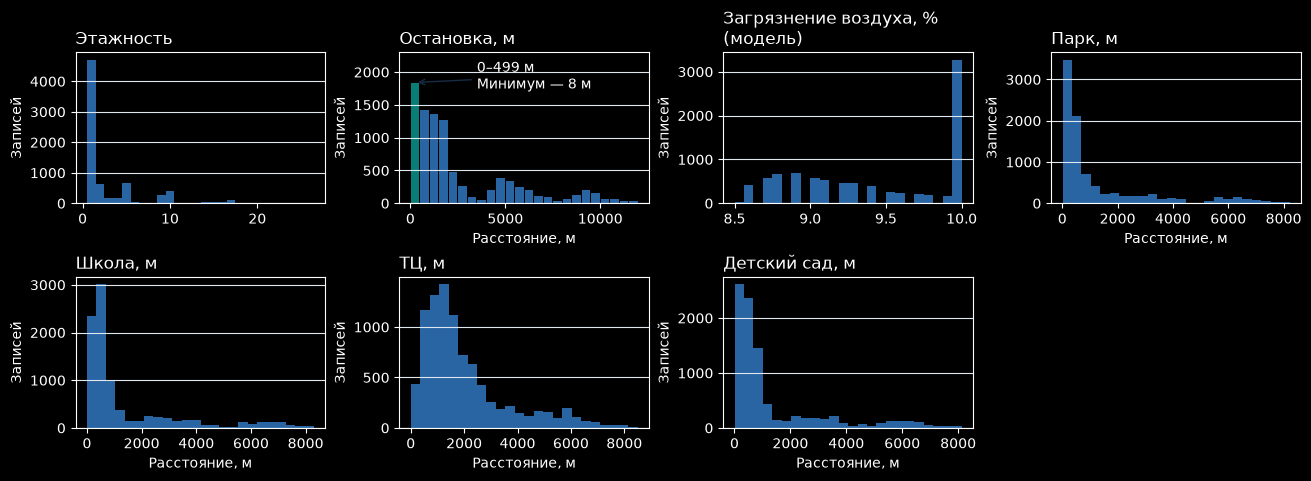

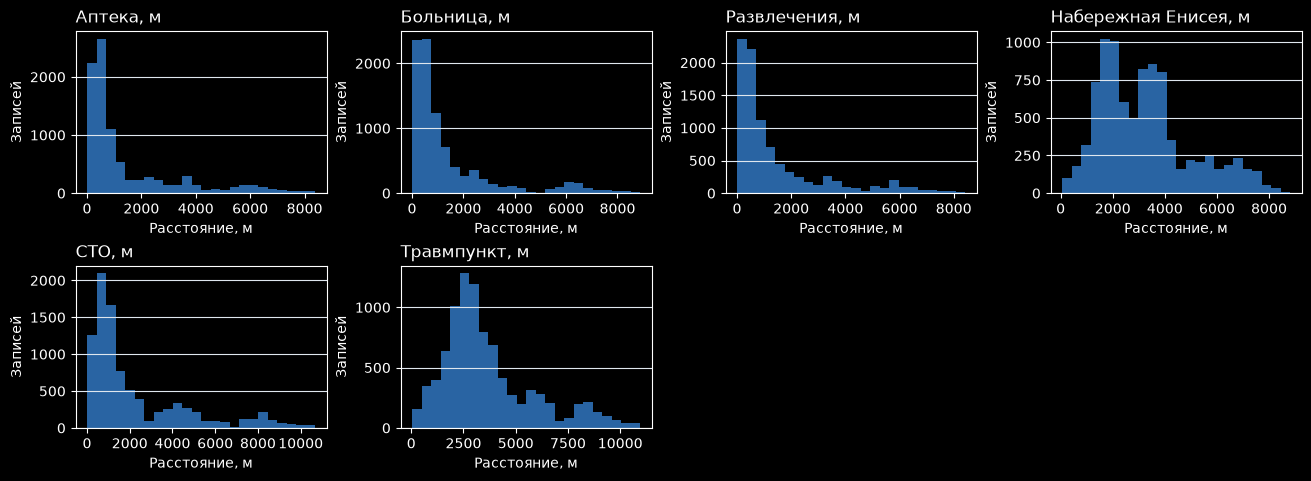

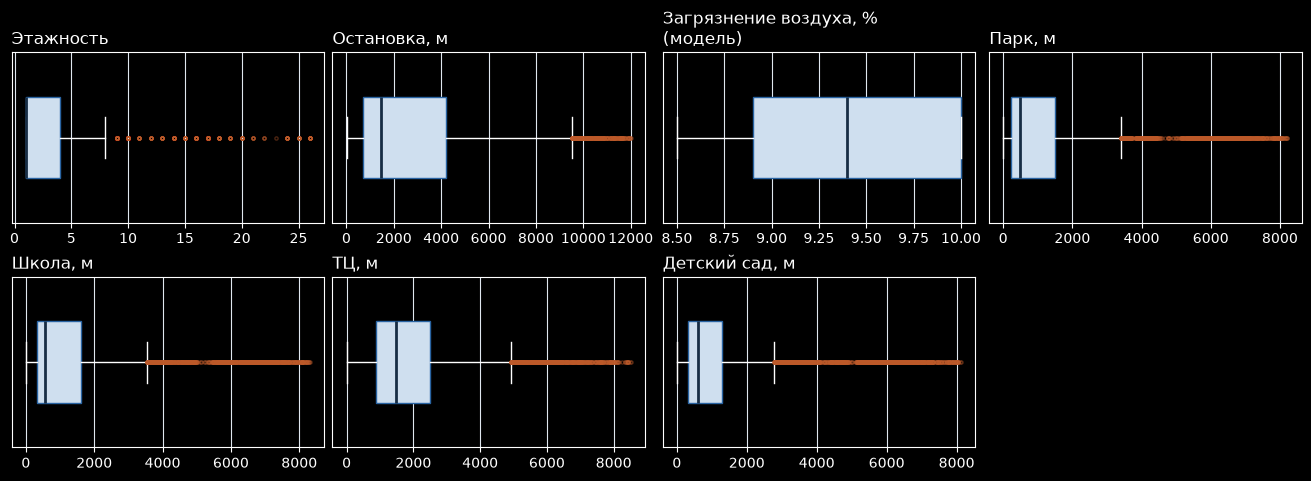

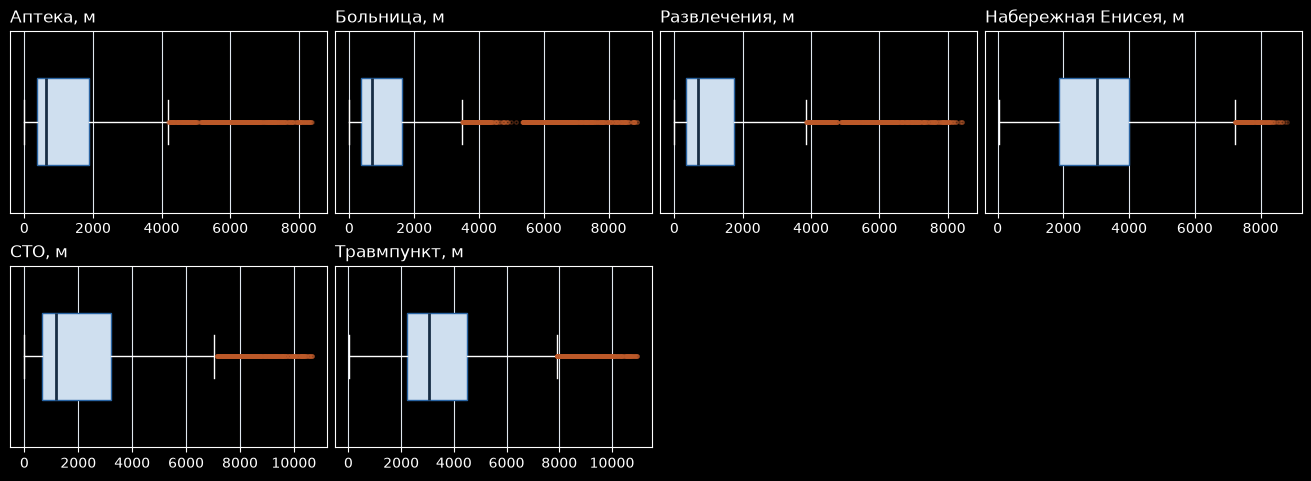

In [3]:
short = dict(zip(data.columns, data.columns))
short[charts.stop] = 'Остановка, м'
charts.panels(numeric[:7], charts.histogram, short, data=data)
charts.panels(numeric[7:], charts.histogram, short, data=data)
charts.panels(numeric[:7], charts.box, short, data=data)
charts.panels(numeric[7:], charts.box, short, data=data)

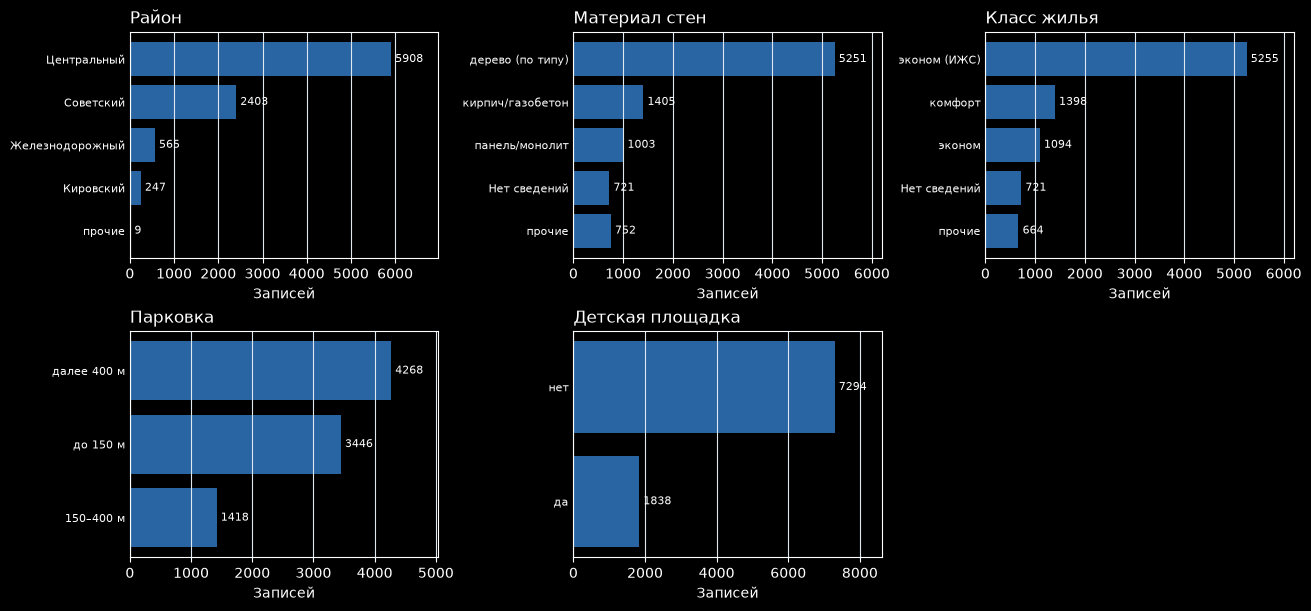

In [4]:
categories = data[categorical].fillna('Нет сведений')
charts.panels(categorical, charts.category, short, ncols=3, height=3,
              geo=charts.read_coordinates(data), raw=categories, data=data)

## 4. Кодирование признаков

Для текстовых признаков используем `get_dummies()`. Служебные поля, «Закрытый двор» и сам целевой столбец исключены из X. Из X также убраны шесть расстояний, из которых напрямую рассчитаны метки. Для описательных графиков они остаются в `data`. Неизвестная этажность сохранена как пропуск.

,Этажность,"Загрязнение воздуха, % (модель)","Парк, м","ТЦ, м","Набережная Енисея, м","СТО, м","Травмпункт, м",Район_Железнодорожный,Район_Кировский,Район_Красноярск (район не определён),...,Класс жилья_бизнес (12+ этажей),Класс жилья_комфорт,Класс жилья_эконом,Класс жилья_эконом (ИЖС),Класс жилья_эконом/комфорт,Парковка_далее 400 м (нет парковки в данных),Парковка_наземная парковка рядом (до 150 м),Парковка_парковка в радиусе 400 м,Детская площадка_да,Детская площадка_нет
0,5.0,9.2,348,722,1135,3703,3418,0,0,0,...,0,1,0,0,0,1,0,0,0,1
1,9.0,9.0,259,670,1109,3638,3335,0,0,0,...,0,1,0,0,0,1,0,0,1,0
2,10.0,10.0,1638,2211,1776,4184,4391,0,0,0,...,0,1,0,0,0,1,0,0,0,1


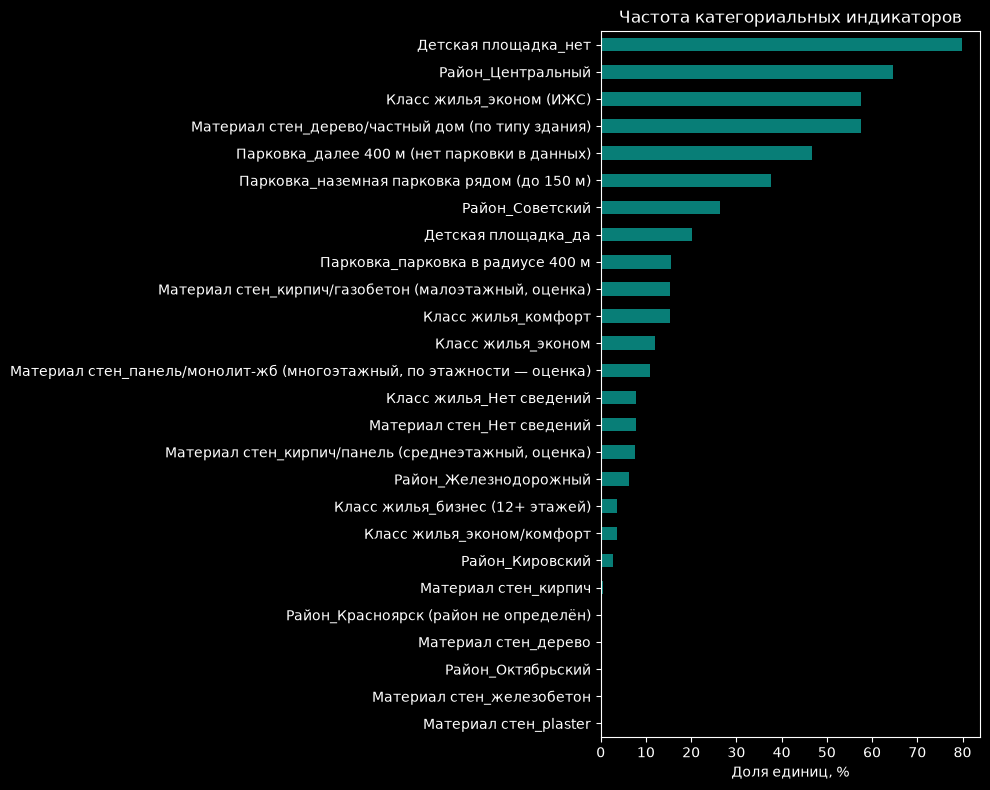

In [5]:
indicators = pd.get_dummies(categories, dtype='int8')
X = data[numeric].drop(columns=charts.profile_distances).join(indicators)
y = data[target]
display(X.head(3))
indicators.mean().mul(100).sort_values().plot.barh(
    figsize=(10, 8), color=charts.teal, xlabel='Доля единиц, %',
    title='Частота категориальных индикаторов',
)
plt.tight_layout()
plt.show()

## 5. Корреляции между числовыми признаками

Коэффициент Спирмена рассчитан между количественными полями. «Тип жильца» — категория без естественного порядка.

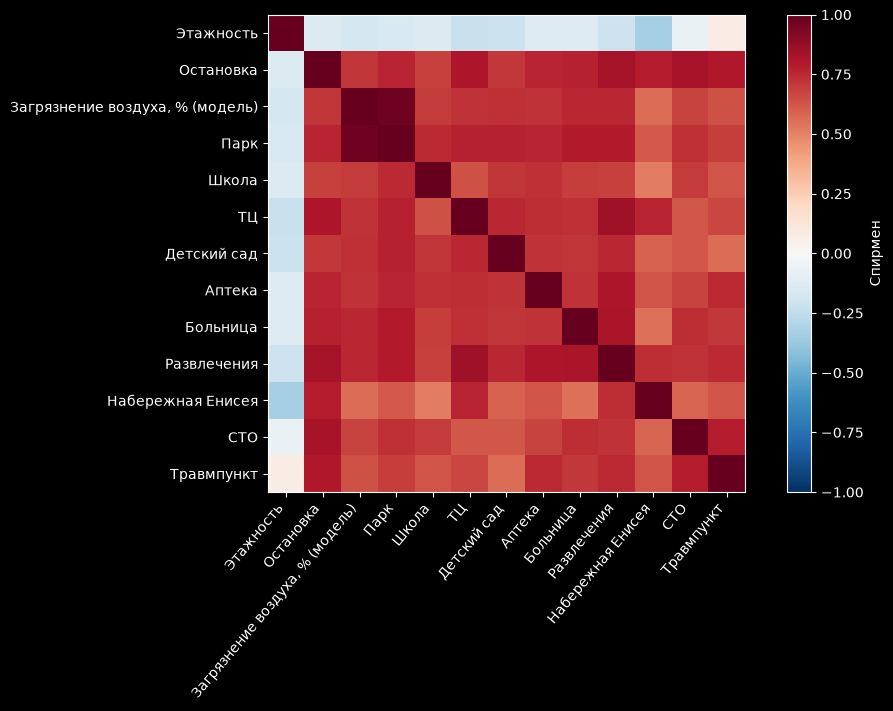

In [6]:
correlations = data[numeric].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 7), layout='constrained')
image = ax.imshow(correlations, cmap='RdBu_r', vmin=-1, vmax=1)
labels = [short[col].removesuffix(', м') for col in numeric]
ax.set_xticks(range(len(labels)), labels, rotation=50, ha='right')
ax.set_yticks(range(len(labels)), labels)
fig.colorbar(image, ax=ax, label='Спирмен')
plt.show()

## 6. Зависимости с целевой переменной

Сравниваем классы по медианам, а районы — по долям классов. Это описательная статистика: часть различий напрямую следует из правил разметки.

,Записей,Доля
Тип жильца,,
Семейная,2481,27.2%
Для одного человека,2332,25.5%
Для автомобилиста,2292,25.1%
Для пожилых людей,2027,22.2%


,"Школа, м","Детский сад, м","Ближайшая остановка, м","Развлечения, м","Аптека, м","Больница, м"
Тип жильца,,,,,,
Для автомобилиста,3646.5,3499.0,6115.5,3521.0,3728.0,3099.5
Для одного человека,554.5,490.0,506.5,353.0,540.0,551.0
Для пожилых людей,490.0,531.0,1240.0,465.0,328.0,337.0
Семейная,314.0,309.0,1509.0,763.0,599.0,688.0


/Users/egorlugovkin/PycharmProjects/desicion/PythonProject/.venv/lib/python3.14/site-packages/pandas/plotting/_matplotlib/boxplot.py:63: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels, **kwargs)


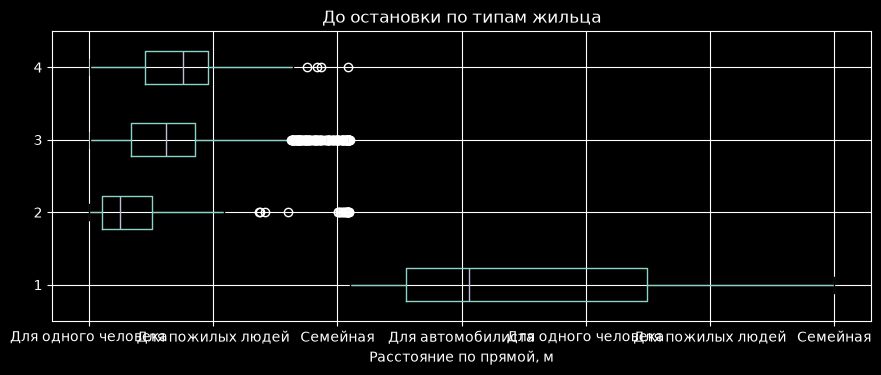

In [7]:
counts = y.value_counts()
display(counts.to_frame('Записей').assign(Доля=counts.div(len(y)).map('{:.1%}'.format)))
medians = data.groupby(target)[charts.profile_distances].median()
display(medians)
data.boxplot(column=charts.stop, by=target, orientation='horizontal', figsize=(9, 4))
plt.suptitle('')
plt.title('До остановки по типам жильца')
plt.xlabel('Расстояние по прямой, м')
plt.tight_layout()
plt.show()

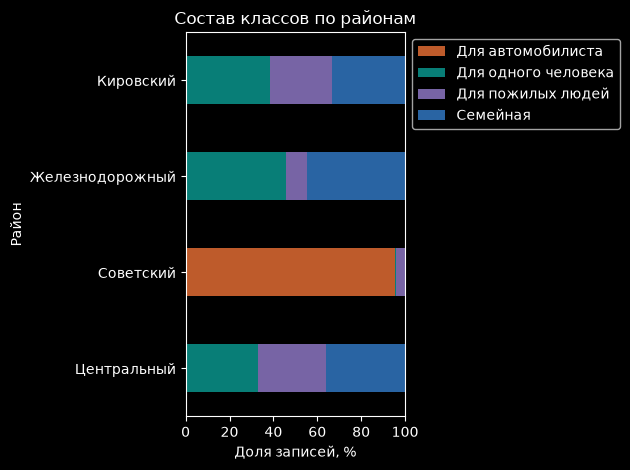

In [8]:
districts = data[charts.district].value_counts().loc[lambda n: n >= 30].index
district_shares = pd.crosstab(data[charts.district], y, normalize='index').loc[districts]
district_shares.mul(100).plot.barh(
    stacked=True, color=charts.class_colors, xlim=(0, 100), xlabel='Доля записей, %',
    title='Состав классов по районам',
)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Семейный класс ближе всего к школе и детсаду по медианам. У класса для одного человека самые низкие медианы расстояний до остановки и развлечений, у класса для пожилых людей — до аптеки и больницы. В Советском районе **95,3%** записей относятся к классу «Для автомобилиста». Район в правило разметки не входит, но распределение связано с удалённостью от остановок и полнотой их разметки.